<a href="https://colab.research.google.com/github/biswal-prem-5677/10xCoders-Platform/blob/main/ai/05_ai_systems/computer_vision/opencv/experiment_digital_image_processing_opencv.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Digital Image Processing using Python & OpenCV
This Google Colab notebook reproduces the image-processing experiments shown in the uploaded laboratory pages.

### Experiments included:
1. Reading, displaying and saving images
2. Resizing images
3. Horizontal, vertical and both-direction flipping
4. Cropping
5. Color spaces: Grayscale, BGR, HSV, XYZ, LAB and CMYK preview
6. Splitting and merging B, G and R channels
7. Grayscale histogram and histogram equalization
8. Color histogram and per-channel equalization
9. Bitwise AND and OR on binary images
10. Binary thresholding
11. Adaptive thresholding
12. Otsu thresholding
13. Erosion
14. Blurring / smoothing
15. Border creation
16. Edge detection: Canny, Sobel and Laplacian
17. Sharpening

## 0. Import Libraries

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

print("OpenCV version:", cv2.__version__)

OpenCV version: 5.0.0


## Helper Functions

In [2]:
def upload_image(color=True):
    uploaded = files.upload()
    if not uploaded:
        raise ValueError("No image was uploaded.")
    filename = next(iter(uploaded))
    data = np.frombuffer(uploaded[filename], np.uint8)
    flag = cv2.IMREAD_COLOR if color else cv2.IMREAD_GRAYSCALE
    image = cv2.imdecode(data, flag)
    if image is None:
        raise ValueError("Could not decode the uploaded image.")
    return filename, image

def show_bgr(image, title="Image", figsize=(7, 5)):
    plt.figure(figsize=figsize)
    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis("off")
    plt.show()

## 1. Reading, Displaying and Saving Image Files

Saving lion 4.jpg to lion 4.jpg
Filename: lion 4.jpg
Shape: (2000, 2000, 3)
Data type: uint8


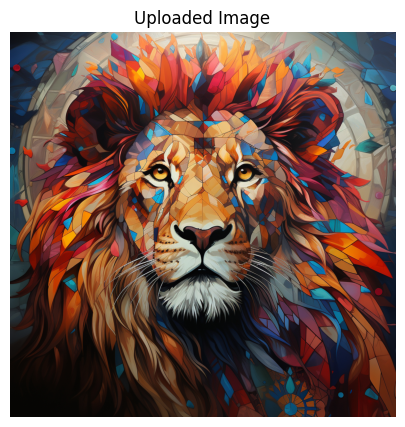

Image saved as saved_image.jpg


In [3]:
filename, img = upload_image(color=True)

print("Filename:", filename)
print("Shape:", img.shape)
print("Data type:", img.dtype)

show_bgr(img, "Uploaded Image")

# Save image
cv2.imwrite("saved_image.jpg", img)
print("Image saved as saved_image.jpg")

## 2. Resizing Image

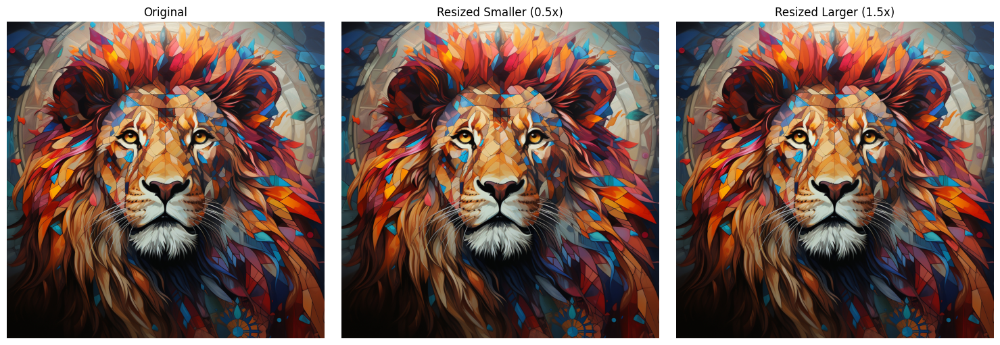

In [4]:
small = cv2.resize(img, None, fx=0.5, fy=0.5, interpolation=cv2.INTER_AREA)
large = cv2.resize(img, None, fx=1.5, fy=1.5, interpolation=cv2.INTER_LINEAR)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Original")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(cv2.cvtColor(small, cv2.COLOR_BGR2RGB))
plt.title("Resized Smaller (0.5x)")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(cv2.cvtColor(large, cv2.COLOR_BGR2RGB))
plt.title("Resized Larger (1.5x)")
plt.axis("off")

plt.tight_layout()
plt.show()

## 3. Flipping Image — Horizontal, Vertical and Both

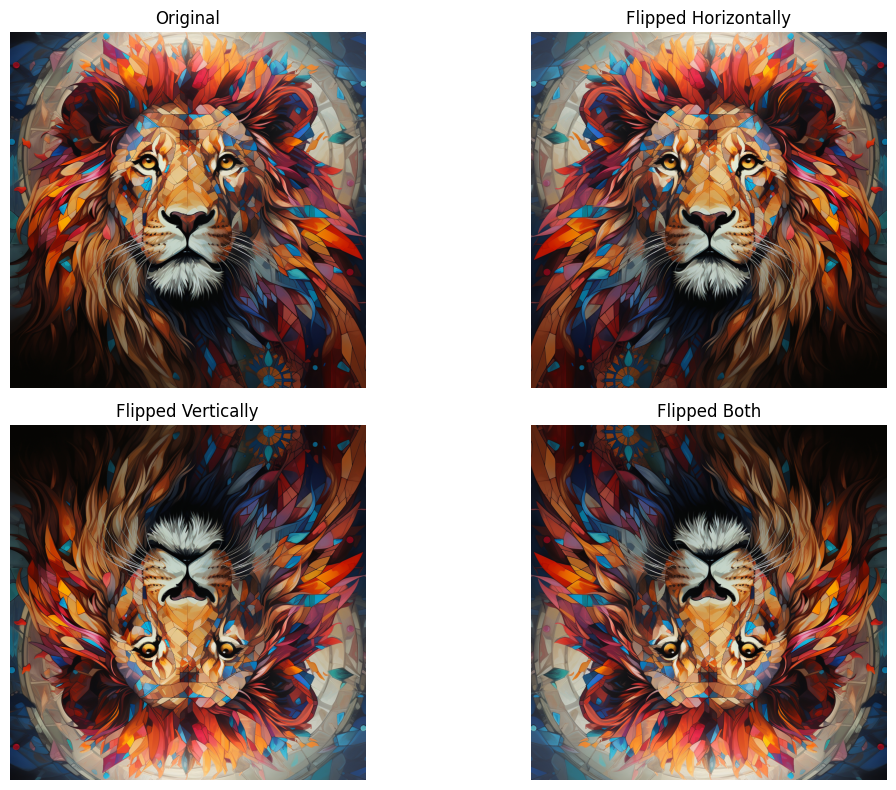

In [5]:
flip_horizontal = cv2.flip(img, 1)
flip_vertical = cv2.flip(img, 0)
flip_both = cv2.flip(img, -1)

images = [img, flip_horizontal, flip_vertical, flip_both]
titles = ["Original", "Flipped Horizontally", "Flipped Vertically", "Flipped Both"]

plt.figure(figsize=(12, 8))
for i, (image, title) in enumerate(zip(images, titles), 1):
    plt.subplot(2, 2, i)
    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis("off")
plt.tight_layout()
plt.show()

## 4. Cropping Image — Center 67%

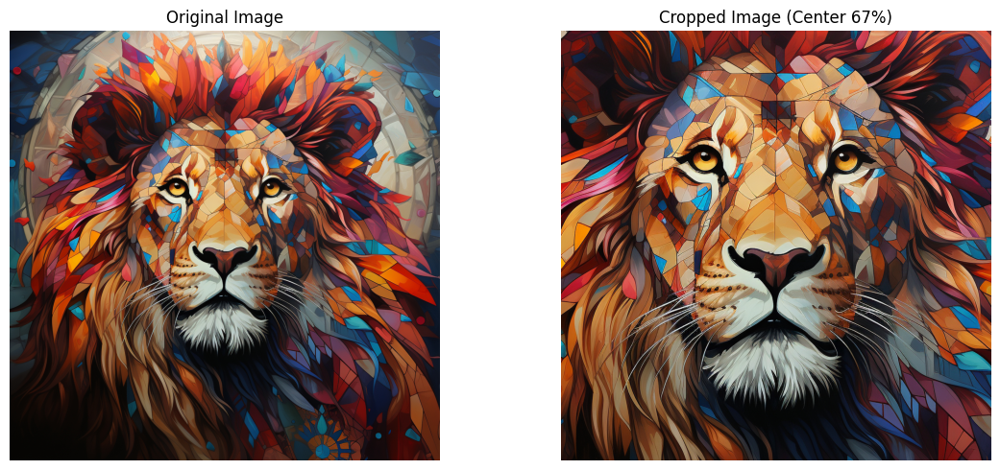

In [6]:
h, w = img.shape[:2]

crop_h = int(0.67 * h)
crop_w = int(0.67 * w)

y1 = (h - crop_h) // 2
y2 = y1 + crop_h
x1 = (w - crop_w) // 2
x2 = x1 + crop_w

cropped = img[y1:y2, x1:x2]

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(cropped, cv2.COLOR_BGR2RGB))
plt.title("Cropped Image (Center 67%)")
plt.axis("off")

plt.tight_layout()
plt.show()

## 5. Switching Between Color Spaces
OpenCV directly supports BGR, grayscale, HSV, XYZ and LAB conversions. CMYK is not a standard direct OpenCV conversion, so a CMYK representation is calculated from RGB for demonstration.

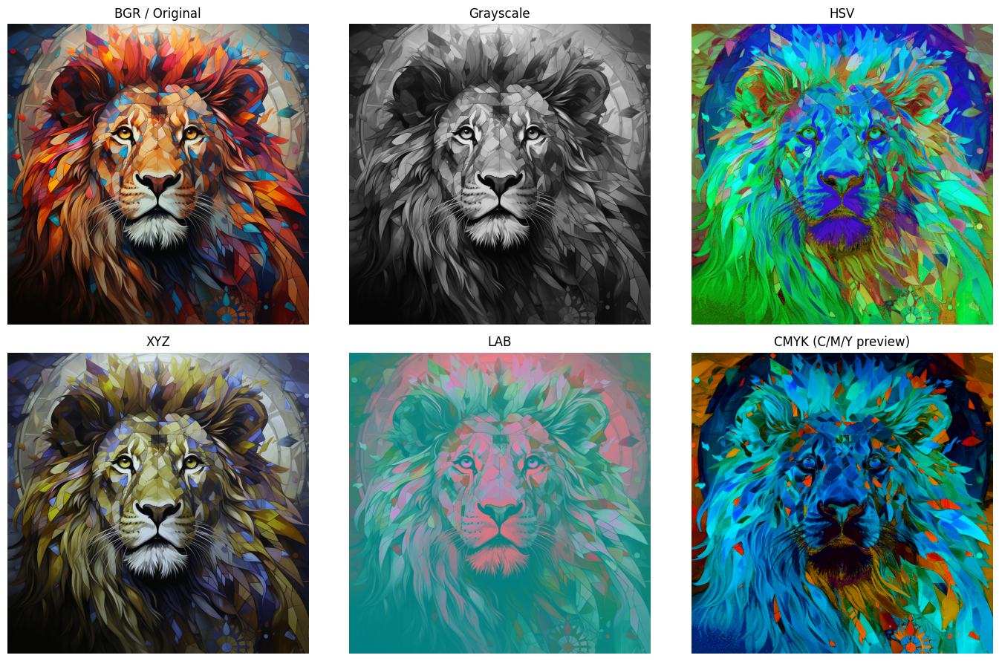

In [7]:
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
xyz = cv2.cvtColor(img, cv2.COLOR_BGR2XYZ)
lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)

# BGR -> RGB -> CMYK
rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0
K = 1 - np.max(rgb, axis=2)
denom = np.where((1 - K) == 0, 1, 1 - K)

C = (1 - rgb[:, :, 0] - K) / denom
M = (1 - rgb[:, :, 1] - K) / denom
Y = (1 - rgb[:, :, 2] - K) / denom
cmyk = np.dstack((C, M, Y, K))

fig, axes = plt.subplots(2, 3, figsize=(14, 9))

axes[0,0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
axes[0,0].set_title("BGR / Original")
axes[0,0].axis("off")

axes[0,1].imshow(gray, cmap="gray")
axes[0,1].set_title("Grayscale")
axes[0,1].axis("off")

axes[0,2].imshow(hsv)
axes[0,2].set_title("HSV")
axes[0,2].axis("off")

axes[1,0].imshow(xyz)
axes[1,0].set_title("XYZ")
axes[1,0].axis("off")

axes[1,1].imshow(lab)
axes[1,1].set_title("LAB")
axes[1,1].axis("off")

axes[1,2].imshow(np.clip(cmyk[:, :, :3], 0, 1))
axes[1,2].set_title("CMYK (C/M/Y preview)")
axes[1,2].axis("off")

plt.tight_layout()
plt.show()

## 6. Splitting Color Image into B, G and R Channels and Merging

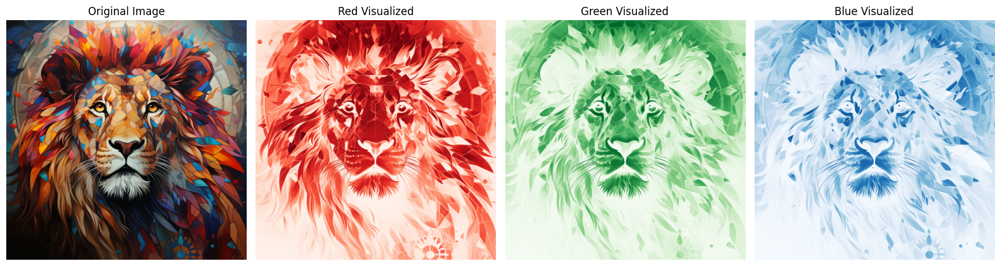

Merged image equals original: True


In [8]:
blue, green, red = cv2.split(img)

plt.figure(figsize=(16, 5))

plt.subplot(1, 4, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 4, 2)
plt.imshow(red, cmap="Reds")
plt.title("Red Visualized")
plt.axis("off")

plt.subplot(1, 4, 3)
plt.imshow(green, cmap="Greens")
plt.title("Green Visualized")
plt.axis("off")

plt.subplot(1, 4, 4)
plt.imshow(blue, cmap="Blues")
plt.title("Blue Visualized")
plt.axis("off")

plt.tight_layout()
plt.show()

merged = cv2.merge([blue, green, red])
print("Merged image equals original:", np.array_equal(img, merged))

## 7. Grayscale Histogram and Histogram Equalization

/tmp/ipykernel_3876/2224541323.py:14: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  axes[1,0].hist(gray.ravel(), 256, [0, 256])
/tmp/ipykernel_3876/2224541323.py:19: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  axes[1,1].hist(equalized_gray.ravel(), 256, [0, 256])


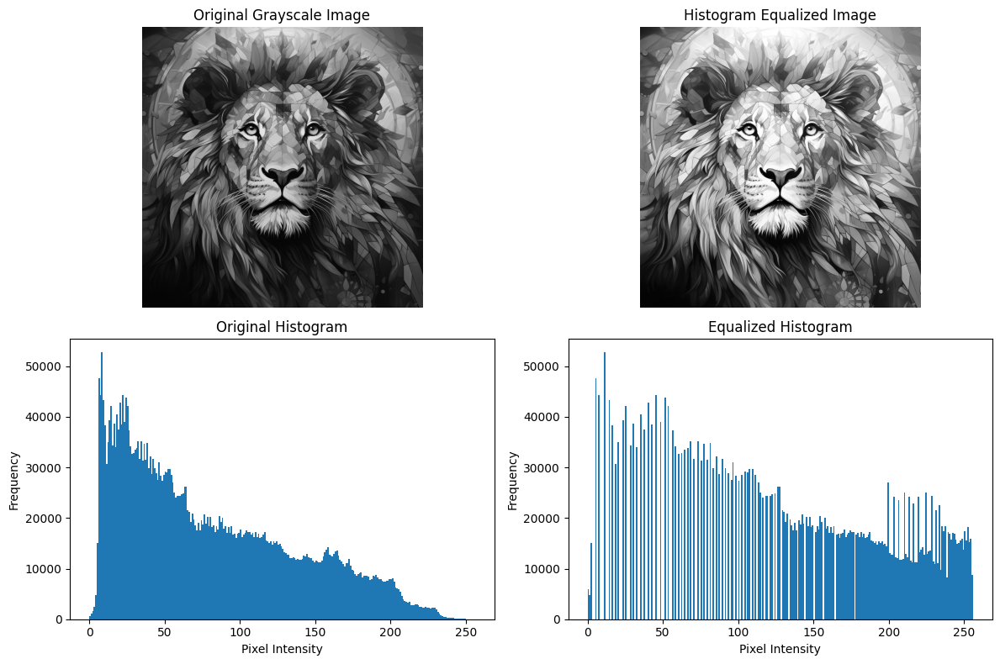

In [9]:
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
equalized_gray = cv2.equalizeHist(gray)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

axes[0,0].imshow(gray, cmap="gray")
axes[0,0].set_title("Original Grayscale Image")
axes[0,0].axis("off")

axes[0,1].imshow(equalized_gray, cmap="gray")
axes[0,1].set_title("Histogram Equalized Image")
axes[0,1].axis("off")

axes[1,0].hist(gray.ravel(), 256, [0, 256])
axes[1,0].set_title("Original Histogram")
axes[1,0].set_xlabel("Pixel Intensity")
axes[1,0].set_ylabel("Frequency")

axes[1,1].hist(equalized_gray.ravel(), 256, [0, 256])
axes[1,1].set_title("Equalized Histogram")
axes[1,1].set_xlabel("Pixel Intensity")
axes[1,1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

## 8. Color Image Histogram and Per-Channel Equalization

/tmp/ipykernel_3876/3090029725.py:4: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  plt.hist(b.ravel(), 256, [0, 256], alpha=0.5, label="Blue")
/tmp/ipykernel_3876/3090029725.py:5: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  plt.hist(g.ravel(), 256, [0, 256], alpha=0.5, label="Green")
/tmp/ipykernel_3876/3090029725.py:6: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  plt.hist(r.ravel(), 256, [0, 256], alpha=0.5, label="Red")


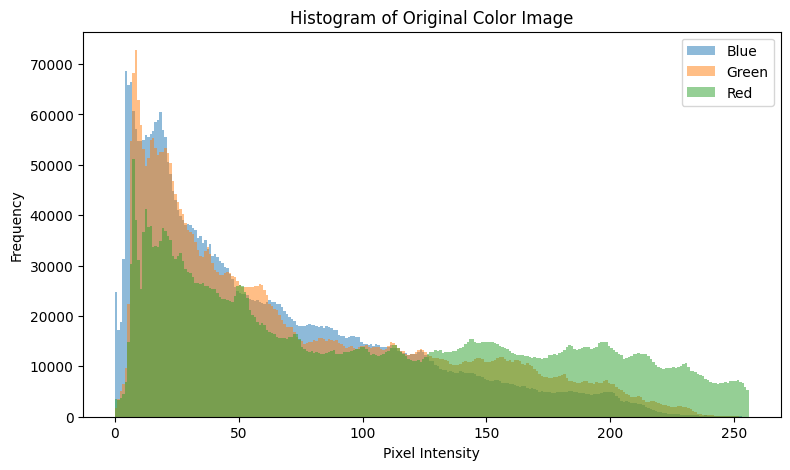

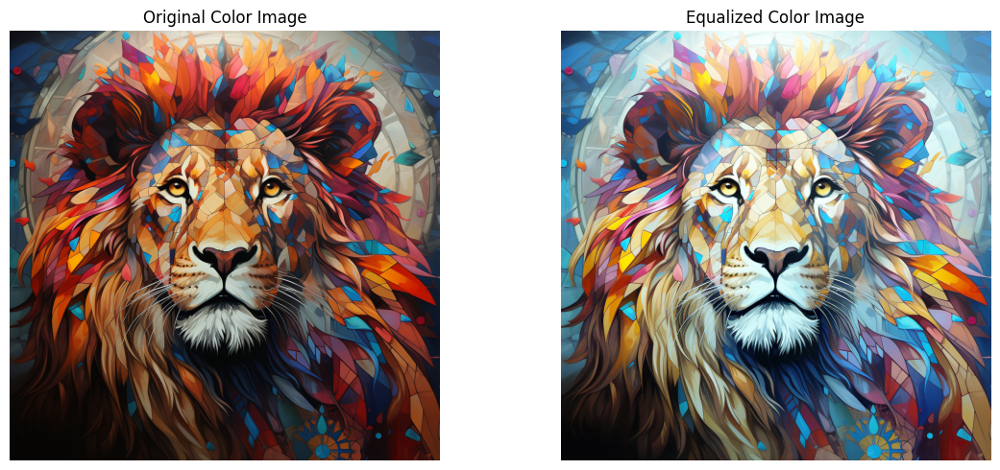

/tmp/ipykernel_3876/3090029725.py:35: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  plt.hist(b_eq.ravel(), 256, [0, 256], alpha=0.5, label="Blue")
/tmp/ipykernel_3876/3090029725.py:36: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  plt.hist(g_eq.ravel(), 256, [0, 256], alpha=0.5, label="Green")
/tmp/ipykernel_3876/3090029725.py:37: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  plt.hist(r_eq.ravel(), 256, [0, 256], alpha=0.5, label="Red")


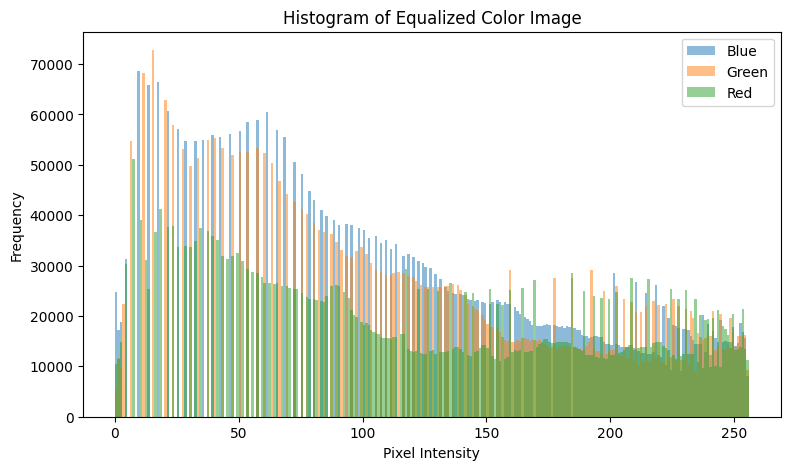

In [10]:
b, g, r = cv2.split(img)

plt.figure(figsize=(9, 5))
plt.hist(b.ravel(), 256, [0, 256], alpha=0.5, label="Blue")
plt.hist(g.ravel(), 256, [0, 256], alpha=0.5, label="Green")
plt.hist(r.ravel(), 256, [0, 256], alpha=0.5, label="Red")
plt.title("Histogram of Original Color Image")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")
plt.legend()
plt.show()

b_eq = cv2.equalizeHist(b)
g_eq = cv2.equalizeHist(g)
r_eq = cv2.equalizeHist(r)

equalized_color = cv2.merge([b_eq, g_eq, r_eq])

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Original Color Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(equalized_color, cv2.COLOR_BGR2RGB))
plt.title("Equalized Color Image")
plt.axis("off")

plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 5))
plt.hist(b_eq.ravel(), 256, [0, 256], alpha=0.5, label="Blue")
plt.hist(g_eq.ravel(), 256, [0, 256], alpha=0.5, label="Green")
plt.hist(r_eq.ravel(), 256, [0, 256], alpha=0.5, label="Red")
plt.title("Histogram of Equalized Color Image")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")
plt.legend()
plt.show()

## 9. Bitwise Operations on Binary Images — AND and OR

Upload TWO images.


Saving lion 4.jpg to lion 4 (1).jpg
Saving lion wallpaper.jpg to lion wallpaper.jpg


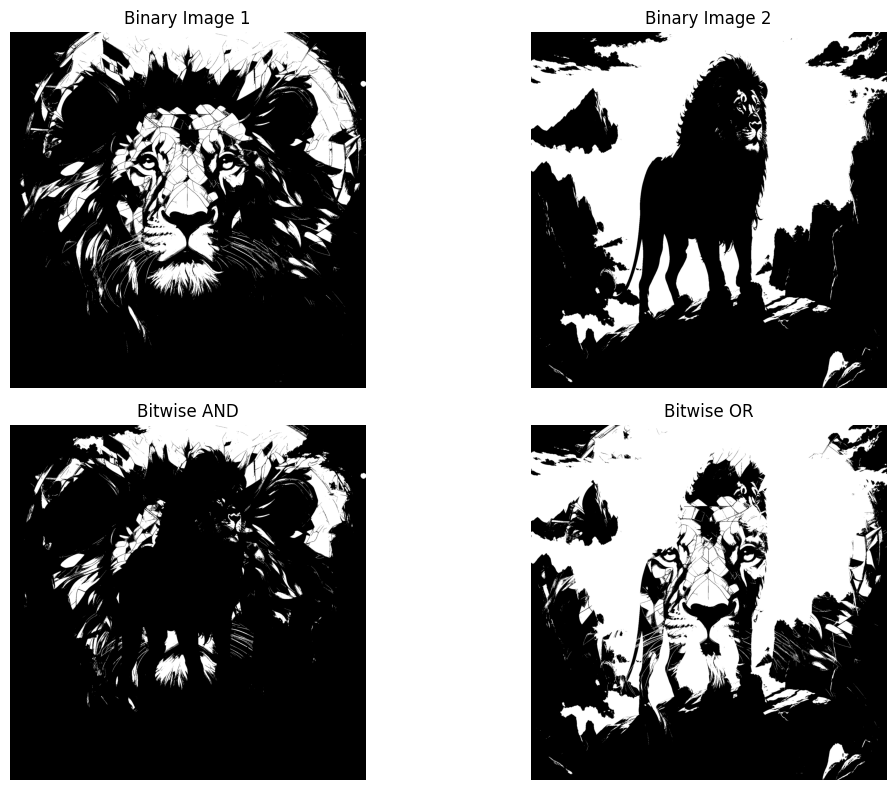

In [11]:
print("Upload TWO images.")
uploaded = files.upload()

if len(uploaded) < 2:
    raise ValueError("Please upload at least two images.")

names = list(uploaded.keys())[:2]

def decode_gray(name):
    data = np.frombuffer(uploaded[name], np.uint8)
    image = cv2.imdecode(data, cv2.IMREAD_GRAYSCALE)
    if image is None:
        raise ValueError(f"Could not decode {name}")
    return image

img1 = decode_gray(names[0])
img2 = decode_gray(names[1])

h1, w1 = img1.shape[:2]
img2 = cv2.resize(img2, (w1, h1), interpolation=cv2.INTER_AREA)

_, binary1 = cv2.threshold(img1, 127, 255, cv2.THRESH_BINARY)
_, binary2 = cv2.threshold(img2, 127, 255, cv2.THRESH_BINARY)

bitwise_and = cv2.bitwise_and(binary1, binary2)
bitwise_or = cv2.bitwise_or(binary1, binary2)

images = [binary1, binary2, bitwise_and, bitwise_or]
titles = ["Binary Image 1", "Binary Image 2", "Bitwise AND", "Bitwise OR"]

plt.figure(figsize=(12, 8))
for i, (image, title) in enumerate(zip(images, titles), 1):
    plt.subplot(2, 2, i)
    plt.imshow(image, cmap="gray")
    plt.title(title)
    plt.axis("off")
plt.tight_layout()
plt.show()

## 10. Binary Thresholding

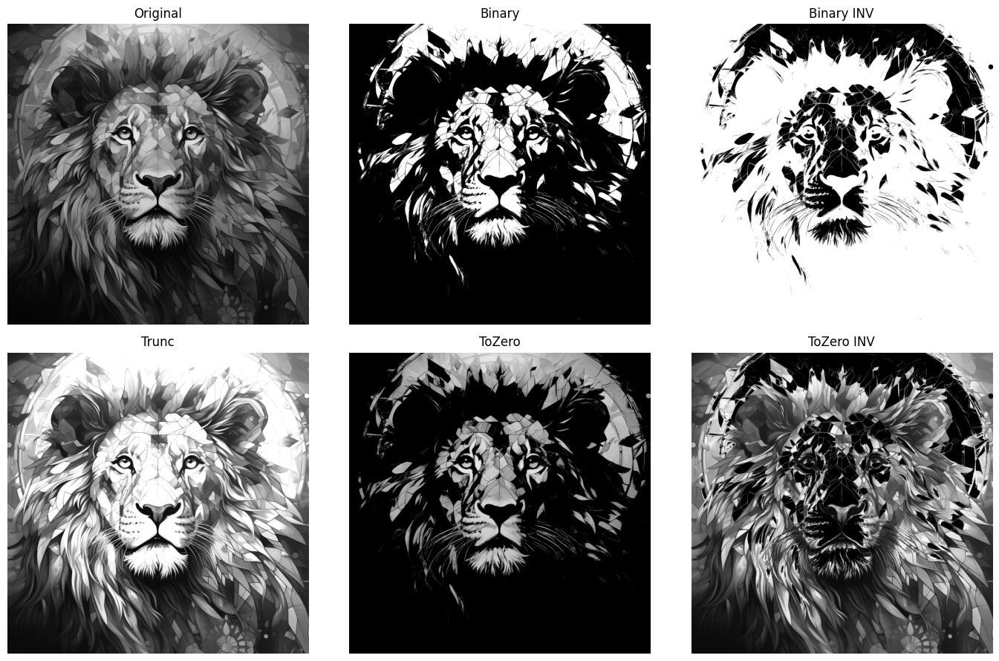

In [12]:
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

_, binary = cv2.threshold(gray, 127, 255, cv2.THRESH_BINARY)
_, binary_inv = cv2.threshold(gray, 127, 255, cv2.THRESH_BINARY_INV)
_, trunc = cv2.threshold(gray, 127, 255, cv2.THRESH_TRUNC)
_, tozero = cv2.threshold(gray, 127, 255, cv2.THRESH_TOZERO)
_, tozero_inv = cv2.threshold(gray, 127, 255, cv2.THRESH_TOZERO_INV)

images = [gray, binary, binary_inv, trunc, tozero, tozero_inv]
titles = ["Original", "Binary", "Binary INV", "Trunc", "ToZero", "ToZero INV"]

plt.figure(figsize=(14, 9))
for i, (image, title) in enumerate(zip(images, titles), 1):
    plt.subplot(2, 3, i)
    plt.imshow(image, cmap="gray")
    plt.title(title)
    plt.axis("off")
plt.tight_layout()
plt.show()

## 11. Adaptive Thresholding

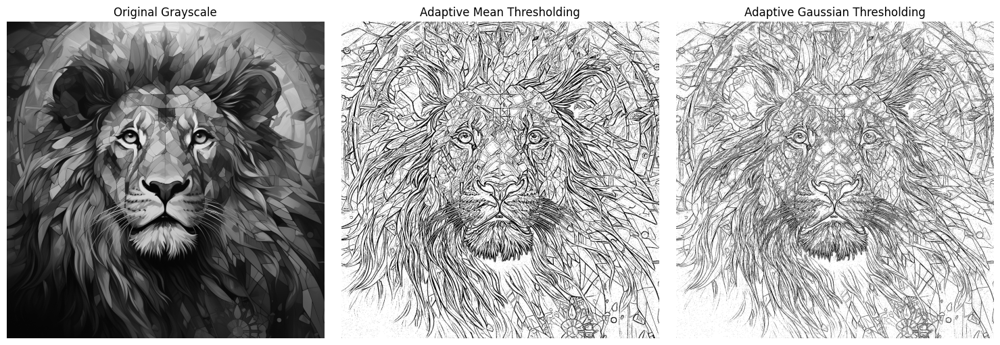

In [13]:
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

adaptive_mean = cv2.adaptiveThreshold(
    gray, 255, cv2.ADAPTIVE_THRESH_MEAN_C,
    cv2.THRESH_BINARY, 11, 2
)

adaptive_gaussian = cv2.adaptiveThreshold(
    gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY, 11, 2
)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(gray, cmap="gray")
plt.title("Original Grayscale")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(adaptive_mean, cmap="gray")
plt.title("Adaptive Mean Thresholding")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(adaptive_gaussian, cmap="gray")
plt.title("Adaptive Gaussian Thresholding")
plt.axis("off")

plt.tight_layout()
plt.show()

## 12. Otsu Thresholding

Otsu threshold value: 93.0


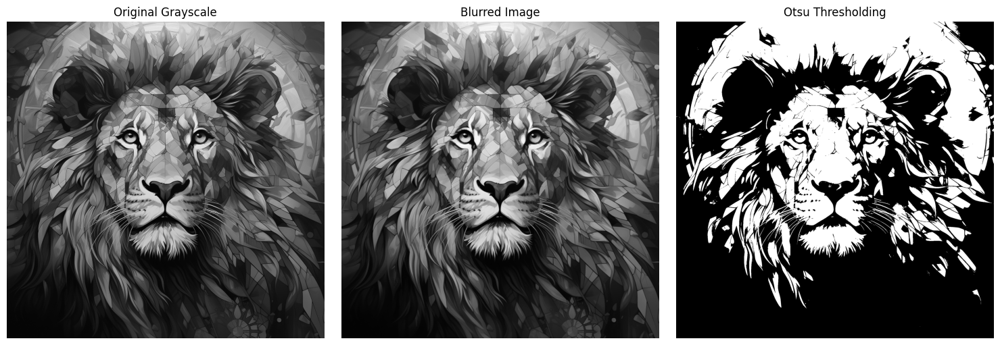

In [14]:
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
blurred = cv2.GaussianBlur(gray, (5, 5), 0)

otsu_value, otsu_thresh = cv2.threshold(
    blurred, 0, 255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

print("Otsu threshold value:", otsu_value)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(gray, cmap="gray")
plt.title("Original Grayscale")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(blurred, cmap="gray")
plt.title("Blurred Image")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(otsu_thresh, cmap="gray")
plt.title("Otsu Thresholding")
plt.axis("off")

plt.tight_layout()
plt.show()

## 13. Erosion

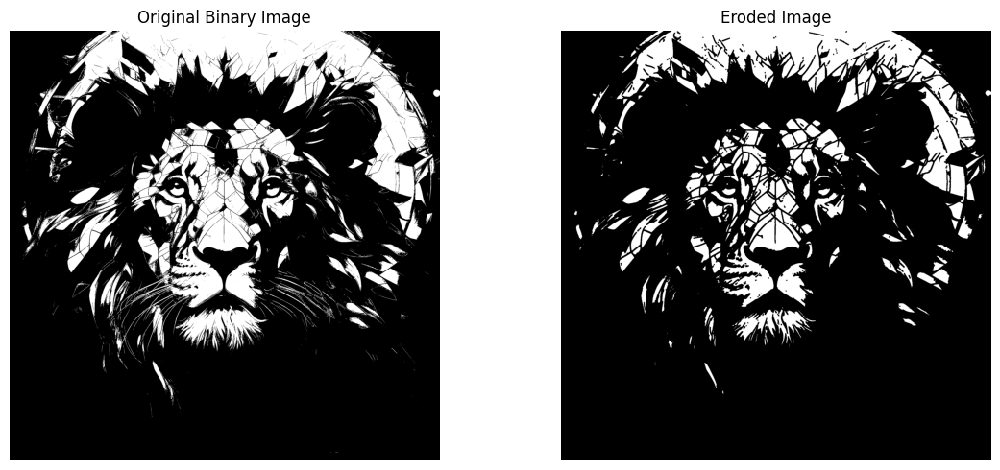

In [15]:
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
_, binary = cv2.threshold(gray, 127, 255, cv2.THRESH_BINARY)

kernel = np.ones((5, 5), np.uint8)
eroded = cv2.erode(binary, kernel, iterations=1)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(binary, cmap="gray")
plt.title("Original Binary Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(eroded, cmap="gray")
plt.title("Eroded Image")
plt.axis("off")

plt.tight_layout()
plt.show()

## 14. Blurring / Smoothing

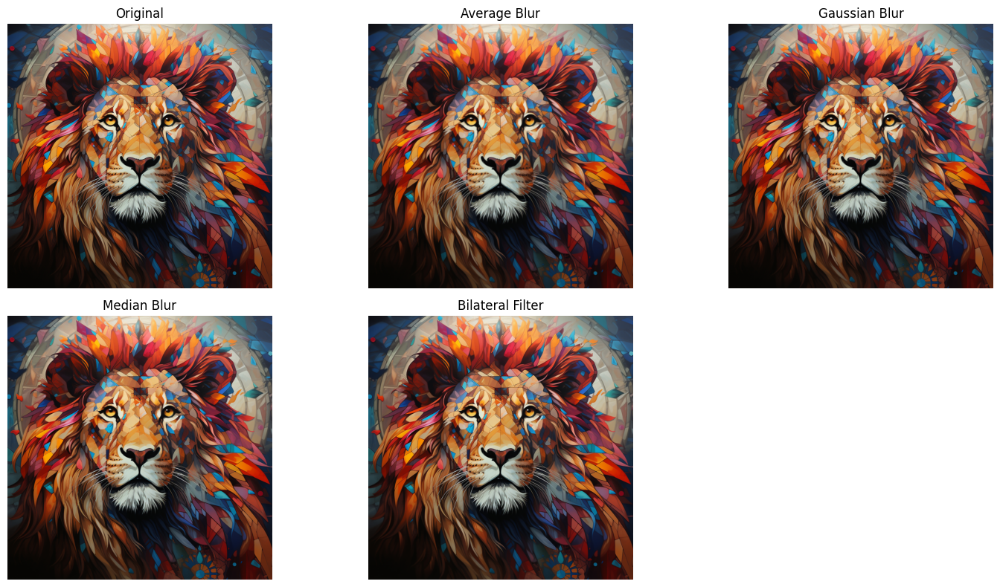

In [16]:
average_blur = cv2.blur(img, (5, 5))
gaussian_blur = cv2.GaussianBlur(img, (5, 5), 0)
median_blur = cv2.medianBlur(img, 5)
bilateral_blur = cv2.bilateralFilter(img, 9, 75, 75)

images = [img, average_blur, gaussian_blur, median_blur, bilateral_blur]
titles = ["Original", "Average Blur", "Gaussian Blur", "Median Blur", "Bilateral Filter"]

plt.figure(figsize=(15, 8))
for i, (image, title) in enumerate(zip(images, titles), 1):
    plt.subplot(2, 3, i)
    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis("off")
plt.tight_layout()
plt.show()

## 15. Create Border Around Image

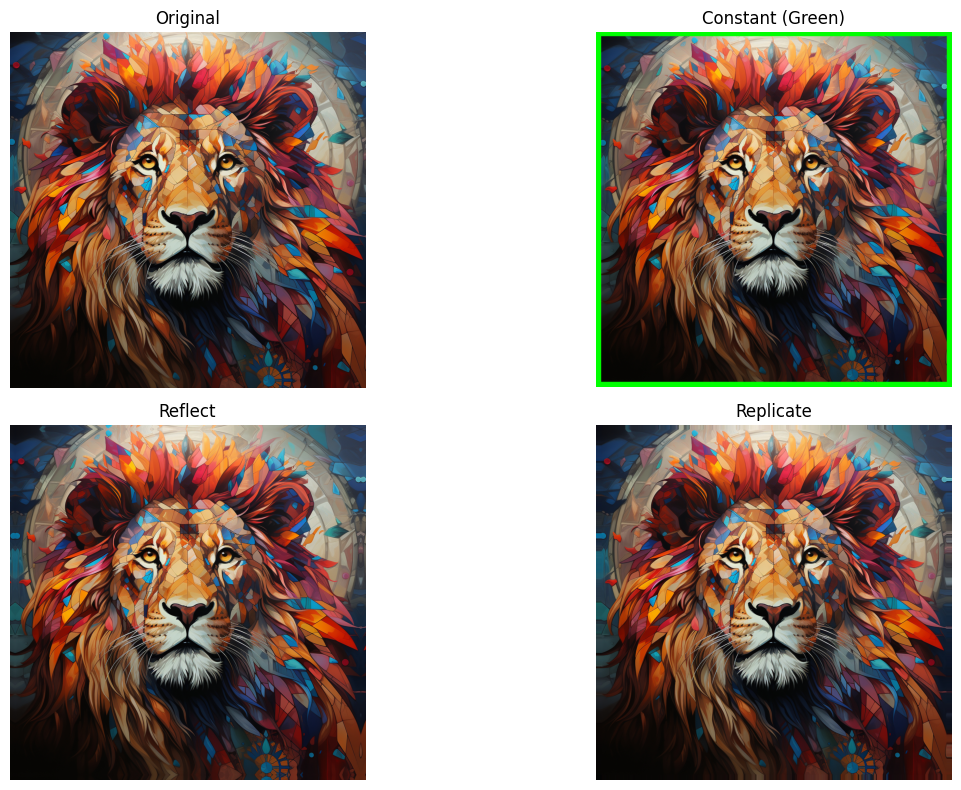

In [17]:
border_size = 30

constant = cv2.copyMakeBorder(
    img, border_size, border_size, border_size, border_size,
    cv2.BORDER_CONSTANT, value=(0, 255, 0)
)

reflect = cv2.copyMakeBorder(
    img, border_size, border_size, border_size, border_size,
    cv2.BORDER_REFLECT
)

replicate = cv2.copyMakeBorder(
    img, border_size, border_size, border_size, border_size,
    cv2.BORDER_REPLICATE
)

images = [img, constant, reflect, replicate]
titles = ["Original", "Constant (Green)", "Reflect", "Replicate"]

plt.figure(figsize=(14, 8))
for i, (image, title) in enumerate(zip(images, titles), 1):
    plt.subplot(2, 2, i)
    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis("off")
plt.tight_layout()
plt.show()

## 16. Edge Detection — Canny, Sobel and Laplacian

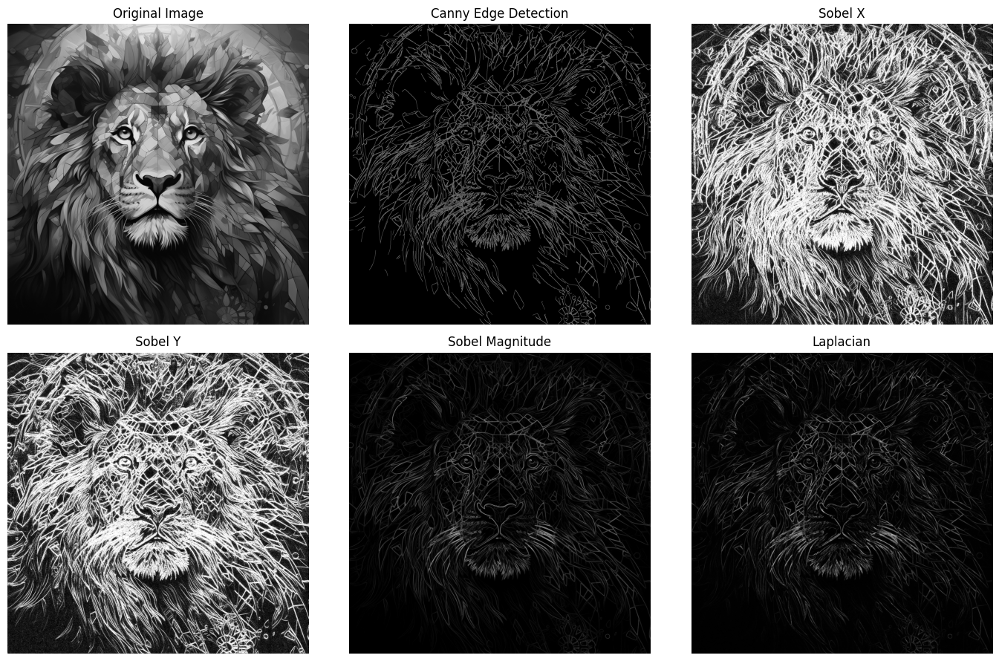

In [18]:
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

edges_canny = cv2.Canny(gray, 100, 200)

sobel_x = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=5)
sobel_y = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=5)

sobel_x_abs = cv2.convertScaleAbs(sobel_x)
sobel_y_abs = cv2.convertScaleAbs(sobel_y)

sobel_magnitude = cv2.magnitude(
    sobel_x.astype(np.float32),
    sobel_y.astype(np.float32)
)
sobel_magnitude = cv2.normalize(
    sobel_magnitude, None, 0, 255, cv2.NORM_MINMAX
).astype(np.uint8)

laplacian = cv2.Laplacian(gray, cv2.CV_64F)
laplacian = cv2.convertScaleAbs(laplacian)

images = [
    gray, edges_canny, sobel_x_abs,
    sobel_y_abs, sobel_magnitude, laplacian
]
titles = [
    "Original Image", "Canny Edge Detection", "Sobel X",
    "Sobel Y", "Sobel Magnitude", "Laplacian"
]

plt.figure(figsize=(14, 9))
for i, (image, title) in enumerate(zip(images, titles), 1):
    plt.subplot(2, 3, i)
    plt.imshow(image, cmap="gray")
    plt.title(title)
    plt.axis("off")
plt.tight_layout()
plt.show()

## 17. Sharpening Image

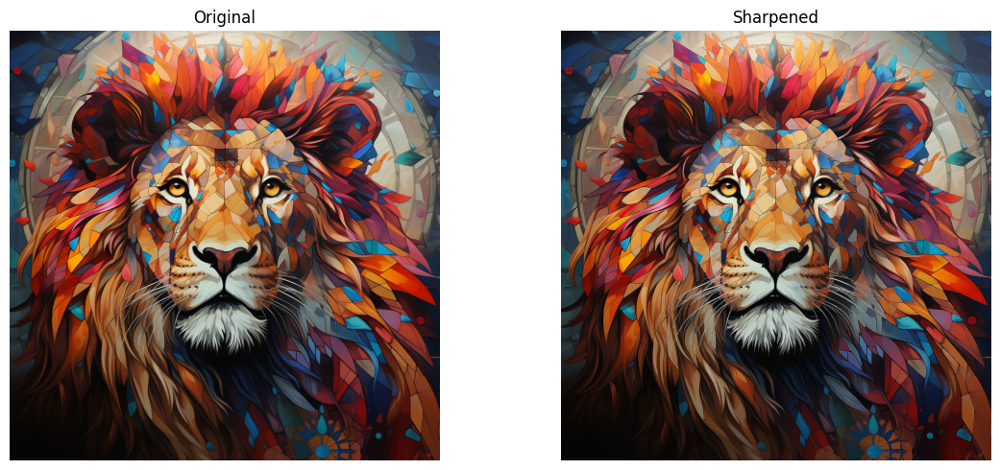

In [19]:
sharpen_kernel = np.array([
    [0, -1,  0],
    [-1, 5, -1],
    [0, -1,  0]
])

sharpened = cv2.filter2D(img, -1, sharpen_kernel)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(sharpened, cv2.COLOR_BGR2RGB))
plt.title("Sharpened")
plt.axis("off")

plt.tight_layout()
plt.show()

## Conclusion and Project Report Guidance
The notebook demonstrates fundamental digital image-processing techniques using Python, OpenCV, NumPy and Matplotlib.

### Suggested report structure
1. Title Page
2. Certificate / Declaration
3. Acknowledgement
4. Abstract
5. Introduction
6. Objectives
7. Software and Hardware Requirements
8. Methodology
9. Implementation / Source Code
10. Experimental Results and Screenshots
11. Discussion
12. Applications
13. Conclusion
14. Future Scope
15. References

### Key concepts for viva
* **OpenCV**: Computer-vision and image-processing library.
* **Grayscale**: Single-channel intensity representation.
* **Thresholding**: Separates image regions using intensity values.
* **Histogram equalization**: Improves contrast by redistributing intensity values.
* **Erosion**: Morphological operation that reduces foreground regions.
* **Otsu thresholding**: Automatically chooses a global threshold from the image histogram.
* **Canny**: Multi-stage edge-detection method.
* **Sobel**: Detects intensity changes in horizontal/vertical directions.
* **Laplacian**: Uses second-order derivatives to highlight rapid intensity changes.
* **Blurring**: Reduces noise and small image variations.
* **Sharpening**: Enhances edges and fine details.